Transformer + LLM -> GGNN


In [ ]:
# downgrade Python về 3.10 để tương thích torch-geometric + pyg-lib
!sudo apt-get update -y
!sudo apt-get install python3.10 python3.10-distutils -y
!sudo update-alternatives --install /usr/bin/python3 python3 /usr/bin/python3.10 1
!wget https://bootstrap.pypa.io/get-pip.py
!python3 get-pip.py


Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [83.6 kB]
Get:5 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Hit:6 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:7 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,160 kB]
Get:8 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Get:11 http://security.ubuntu.com/ubuntu jammy-security/restricted amd64 Packages [6,059 kB]
Get:12 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu ja

In [ ]:
# ============================
# Cell 1 — Install PyTorch 2.3.0 + PyG (compatible với Python 3.10)
# ============================

import sys
print("Python:", sys.version)

# 1) Install PyTorch 2.3.0 + CUDA 12.1
!pip install --upgrade pip
!pip install torch==2.3.0+cu121 torchvision==0.18.0+cu121 torchaudio==2.3.0+cu121 --index-url https://download.pytorch.org/whl/cu121

# 2) Install PyTorch Geometric (đầy đủ ops)
TORCH_VER = "2.3.0"
CU_VER = "cu121"
PYG_URL = f"https://data.pyg.org/whl/torch-{TORCH_VER}+{CU_VER}.html"

!pip install pyg-lib torch-scatter torch-sparse torch-cluster torch-spline-conv torch-geometric -f {PYG_URL}

# 3) Install extra packages
!pip install imbalanced-learn pyarrow sentencepiece einops accelerate transformers==4.44.2

# Kiểm tra
import torch
import torch_geometric
from torch_geometric.nn import GatedGraphConv
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("torch_geometric:", torch_geometric.__version__)
print("GatedGraphConv OK")


Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.9/780.9 MB 37.9 MB/s  0:00:07
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 183.2 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 140.7 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 236.0 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 41.8 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 204.3 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 35.2 MB/s  0:00:08
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 125.7 MB/s  0:00:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 188.8 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 197.5 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 183.3 MB/s  0:00:00
     ━━━

In [ ]:
#cell 2a
# @title Global Config (recall-first + feature-token Transformer + LLM)
import torch, numpy as np

CFG = {
    # HW
    "device": "cuda" if torch.cuda.is_available() else "cpu",

    # GNN core
    "hidden_dim": 128,
    "steps": 5,

    # Sampler/loader
    "neighbors": [25, 25],
    "batch_size": 8192,
    "num_workers": 2,
    "pin_memory": bool(torch.cuda.is_available()),

    # Train
    "epochs_warmup": 2,
    "epochs_main": 8,
    "lr": 2e-3,
    "weight_decay": 1e-4,

    # Graph-SMOTE (hạn chế lệch phân phối)
    "smote": {
        "target_pos": 0.08,       # giảm target_pos: đỡ méo phân phối
        "k": 7,                   # KNN bớt agressive
        "max_per_pos": 2,         # mỗi cạnh dương sinh ít hơn
        "halo_hops": 1,           # bán kính nhỏ lại
        "balance_neg": True,
        "max_candidates": 100_000,
        "max_total": 20_000,      # synthetic cap nhỏ hơn
        "random_state": 42,
    },

    # Calibration & threshold
    "calibration": {"use_temperature": True},
    "threshold_policy": "recall_target",
    "recall_target": 0.90,
    "business_cap": 0.0,

    # Txn-to-Txn attention (mặc định on-the-fly)
    "txn_attention": {
        "enabled": True,
        "k_neighbors": 16,
        "num_heads": 8,
        "share_party_only": True,
        "offline_graph": False,  # bật True nếu đã build tx_edge_index ở 8B
    },

    # Node Transformer + LLM
    "node_transformer": {
        "enabled": True,
        "mode": "ft",        # NEW: mỗi feature là 1 token
        "d_model": 192,
        "nhead": 8,
        "nlayers": 3,
        "dropout": 0.1,
        "use_llm": True,
        "llm_dim": 0,        # set động sau 8C
    },

    # LLM encoder
    "llm": {
        "hf_model": "intfloat/multilingual-e5-base",  # 768-d
        "max_length": 128,
        "batch_size_texts": 4096,
        "normalize": True,
        "prefix": "passage: ",
    },

    # Loss config
    "loss": {"type": "focal", "alpha": 0.75, "gamma": 2.0, "label_smoothing": 0.0},
}

np.random.seed(42)


In [ ]:
# cell 2aa (REPLACED)
CFG["neighbors"] = [25, 25]
CFG["hidden_dim"] = 128
CFG["steps"] = 5


In [ ]:
# cell 2 (UPDATED)
# @title Imports & global config (A100 80GB optimized + anti-fragmentation)
import os, gc, math, sys, time
# chống phân mảnh VRAM cho cudaMalloc (đặt càng sớm càng tốt)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.model_selection import train_test_split

from torch_geometric.data import Data
from torch_geometric.loader import LinkNeighborLoader
from torch_geometric.nn import GatedGraphConv

# BLAS threads hạn chế nhiễu CPU
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# GPU perf
torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")  # TF32/FP16 trên A100

device = "cuda" if torch.cuda.is_available() else "cpu"

# Tùy chọn: bật/ tắt xây "offline txn graph" để dùng trong cell 8B
# False = mặc định KHÔNG build, chỉ dùng attention on-the-fly trong batch → nhanh hơn, không giảm hiệu quả.
CFG.setdefault("txn_attention", {})
CFG["txn_attention"].setdefault("offline_graph", False)

device


'cuda'

In [ ]:
#cell 3
#@title Mount Google Drive & dataset path
from google.colab import drive
drive.mount('/content/drive')

# Sửa đường dẫn CSV của bạn ở đây:
# Ví dụ: "Drive của tôi -> Colab Notebooks -> file.csv"
DATA_CSV = "/content/drive/MyDrive/Colab Notebooks/Online Payments Fraud Analysis-Detection.csv"  # <-- đổi lại đúng tên file

# Nếu dataset quá lớn và muốn thử nhanh, có thể đọc n dòng đầu:
N_ROWS = None  # set ví dụ 1_000_000 để demo nhanh

assert os.path.exists(DATA_CSV), f"Không thấy file: {DATA_CSV}"


Mounted at /content/drive


In [ ]:
#cell 4
#@title Load CSV memory-friendly
read_kwargs = dict(
    low_memory=False,
)

df = pd.read_csv(DATA_CSV, nrows=N_ROWS, **read_kwargs)
print(df.shape)
df.head()


(6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
#cell 5
#@title Feature Engineering helper

# Chuẩn tên cột về dạng tiêu chuẩn nếu có khác biệt nhỏ
colmap = {c.lower(): c for c in df.columns}
def pick(*names):
    for n in names:
        if n in df.columns: return n
        if n in colmap: return colmap[n]
    return None

C_STEP   = pick("step")
C_TYPE   = pick("type")
C_AMOUNT = pick("amount")
C_OBO    = pick("oldbalanceOrg")
C_NBO    = pick("newbalanceOrig")
C_OBD    = pick("oldbalanceDest")
C_NBD    = pick("newbalanceDest")
C_ORIG   = pick("nameOrig")
C_DEST   = pick("nameDest")
C_LABEL  = pick("isFraud")  # nhãn gian lận trên giao dịch (edge)

required = [C_STEP, C_TYPE, C_AMOUNT, C_ORIG, C_DEST, C_LABEL]
assert all(required), f"Thiếu cột bắt buộc, tìm thấy: {required}"

# Ép kiểu
num_cols = [c for c in [C_STEP, C_AMOUNT, C_OBO, C_NBO, C_OBD, C_NBD] if c in df.columns]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Tạo đặc trưng edge
df["hour"] = (df[C_STEP] % 24).astype("float32")
df["day"]  = (df[C_STEP] // 24).astype("float32")

if C_OBO in df and C_NBO in df:
    df["error_orig"] = (df[C_OBO] - (df[C_NBO] + df[C_AMOUNT])).astype("float32")
else:
    df["error_orig"] = 0.0

if C_OBD in df and C_NBD in df:
    df["error_dest"] = (df[C_OBD] + df[C_AMOUNT] - df[C_NBD]).astype("float32")
else:
    df["error_dest"] = 0.0

df["label"] = df[C_LABEL].astype("int8")

# Chọn tập cột feature dạng số cho edge
edge_num_feats = ["hour", "day", "error_orig", "error_dest"]
if C_AMOUNT: edge_num_feats = [C_AMOUNT] + edge_num_feats

edge_cat_feats = []
if C_TYPE: edge_cat_feats = [C_TYPE]

print("edge_num_feats:", edge_num_feats)
print("edge_cat_feats:", edge_cat_feats)


edge_num_feats: ['amount', 'hour', 'day', 'error_orig', 'error_dest']
edge_cat_feats: ['type']


In [ ]:
#cell 6
#@title Temporal split (80/10/10) theo 'step'
assert C_STEP in df

step_sorted = np.sort(df[C_STEP].unique())
cut1 = step_sorted[int(0.8 * len(step_sorted))]
cut2 = step_sorted[int(0.9 * len(step_sorted))]

train_mask = df[C_STEP] < cut1
val_mask   = (df[C_STEP] >= cut1) & (df[C_STEP] < cut2)
test_mask  = df[C_STEP] >= cut2

print("Train/Val/Test sizes:", train_mask.sum(), val_mask.sum(), test_mask.sum())


Train/Val/Test sizes: 6239040 54732 68848


In [ ]:
#cell 7
#tạo edges mở rộng cho smote sau này
#@title Fit ColumnTransformer cho edge features (one-hot type)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(with_mean=True, with_std=True), edge_num_feats),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), edge_cat_feats)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Fit trên train để tránh rò rỉ
edge_train = df.loc[train_mask, edge_num_feats + edge_cat_feats]
preprocess.fit(edge_train)

# Transform toàn bộ (để có sẵn nếu muốn so sánh baseline hoặc SMOTE)
edge_X = preprocess.transform(df[edge_num_feats + edge_cat_feats]).astype("float32")
print(edge_X.shape)


(6362620, 10)


In [ ]:
#cell 8
#@title Build graph (nodes = accounts, edges = transactions)
# Map account -> node id
acc = pd.Index(pd.concat([df[C_ORIG], df[C_DEST]]).unique())
acc_to_id = pd.Series(np.arange(len(acc), dtype=np.int64), index=acc)

src = acc_to_id.loc[df[C_ORIG]].to_numpy()
dst = acc_to_id.loc[df[C_DEST]].to_numpy()

# Edge index
edge_index = torch.tensor(np.vstack([src, dst]), dtype=torch.long)

# Edge labels (fraud flag trên giao dịch)
edge_label = torch.tensor(df["label"].to_numpy(), dtype=torch.float32)

# Train/Val/Test index cho edge labels
eidx = np.arange(len(df), dtype=np.int64)
train_eidx = torch.tensor(eidx[train_mask.values])
val_eidx   = torch.tensor(eidx[val_mask.values])
test_eidx  = torch.tensor(eidx[test_mask.values])

# Node features: aggregate đơn giản theo account
# out/in count + sum/mean amount + cờ merchant (tên bắt đầu bằng 'M')
n = len(acc)
node_feats = pd.DataFrame(index=acc, data={"is_merchant": acc.str.startswith("M").astype("float32")})

grp_out = df.groupby(C_ORIG)[C_AMOUNT].agg(out_count="count", out_sum="sum", out_mean="mean")
grp_in  = df.groupby(C_DEST)[C_AMOUNT].agg(in_count="count",  in_sum="sum",  in_mean="mean")

node_feats = node_feats.join(grp_out, how="left").join(grp_in, how="left").fillna(0.0)

# Chuẩn hoá đơn giản
for c in node_feats.columns:
    node_feats[c] = node_feats[c].astype("float32")
    if node_feats[c].std() > 0:
        node_feats[c] = (node_feats[c] - node_feats[c].mean()) / (node_feats[c].std() + 1e-6)

x = torch.tensor(node_feats.to_numpy(), dtype=torch.float32)

data = Data(
    x=x,
    edge_index=edge_index,
)

# Lưu các chỉ số và nhãn edges tách riêng để dùng với LinkNeighborLoader
data.num_nodes = x.size(0)
EDGE_LABEL = edge_label
TRAIN_EIDX = train_eidx
VAL_EIDX = val_eidx
TEST_EIDX = test_eidx

data


Data(x=[9073900, 7], edge_index=[2, 6362620], num_nodes=9073900)

In [ ]:
# cell 8a
CFG["txn_attention"]["enabled"] = True
CFG["txn_attention"]["num_heads"] = 8
CFG["txn_attention"]["k_neighbors"] = 16
CFG["txn_attention"]["share_party_only"] = True
CFG["txn_attention"]["offline_graph"] = True  # bật build tx_edge_index ở 8B


In [ ]:
# cell 8B (UPDATED, faster)
# TX1 (FAST)
# @title Transaction-to-Transaction Graph (optional offline build)
# Mặc định: KHÔNG build tx_edge_index để tăng tốc. Attention txn dùng "on-the-fly" đã có trong model.
# Nếu cần phân tích ngoại tuyến, đặt CFG["txn_attention"]["offline_graph"]=True trước khi chạy.

import numpy as np, pandas as pd, torch

if CFG["txn_attention"].get("offline_graph", False):
    TIME_WINDOW = 24
    K_TXN_NEI   = 5

    # map người gửi/nhận sang id nút đã có ở cell 8
    SRC = acc_to_id.loc[df[C_ORIG]].to_numpy()
    DST = acc_to_id.loc[df[C_DEST]].to_numpy()
    steps = df[C_STEP].to_numpy()

    def _pairs_by_group_fast(ids: np.ndarray, steps: np.ndarray, time_window: int, k_nei: int):
        # sắp theo (id, step) và nối k lân cận gần nhất với ràng buộc step_diff <= window
        order = np.lexsort((steps, ids))
        ids_s = ids[order]; st_s = steps[order]; idx_s = order
        pairs = []
        for k in range(1, k_nei+1):
            i = idx_s[:-k]; j = idx_s[k:]
            same = ids_s[:-k] == ids_s[k:]
            ok = same & ((st_s[k:] - st_s[:-k]) <= time_window)
            if np.any(ok):
                pairs.append(np.stack([i[ok], j[ok]], axis=1))
        if pairs:
            pairs = np.concatenate(pairs, axis=0)
        else:
            pairs = np.zeros((0,2), dtype=np.int64)
        return pairs

    pairs_o = _pairs_by_group_fast(SRC, steps, TIME_WINDOW, K_TXN_NEI)
    pairs_d = _pairs_by_group_fast(DST, steps, TIME_WINDOW, K_TXN_NEI)

    pairs = np.vstack([pairs_o, pairs_d])
    pairs = np.unique(pairs, axis=0)
    # vô hướng
    pairs_all = np.vstack([pairs, pairs[:, [1,0]]])
    pairs_all = np.unique(pairs_all, axis=0)

    tx_edge_index = torch.tensor(pairs_all.T, dtype=torch.long)
    print("Transaction graph (offline):", tx_edge_index.size(), " (txn nodes =", len(df), ")")
else:
    tx_edge_index = None
    print("Transaction graph OFF. Using on-the-fly masked attention inside batches.")


Transaction graph (offline): torch.Size([2, 10964426])  (txn nodes = 6362620 )


In [ ]:
# cell 8C (REPLACED) — LLM on GPU-first with automatic CPU offload
import os, gc, psutil, torch, numpy as np, pandas as pd
from transformers import AutoTokenizer, AutoModel

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 1) Raw node stats -> text
raw_nf = pd.DataFrame(index=acc, data={"is_merchant": acc.str.startswith("M").astype(int)})
grp_out_raw = df.groupby(C_ORIG)[C_AMOUNT].agg(out_count="count", out_sum="sum", out_mean="mean")
grp_in_raw  = df.groupby(C_DEST)[C_AMOUNT].agg(in_count="count",  in_sum="sum",  in_mean="mean")
raw_nf = raw_nf.join(grp_out_raw, how="left").join(grp_in_raw, how="left").fillna(0.0)

pref = CFG["llm"]["prefix"]
def _fmt(v, nd=2):
    try: return f"{float(v):.{nd}f}"
    except: return "0.00"

texts = []
for aid, is_merchant, out_count, out_sum, out_mean, in_count, in_sum, in_mean in raw_nf.itertuples(index=True, name=None):
    texts.append(
        f"{pref}account_id={aid} ; "
        f"type={'merchant' if int(is_merchant)>0 else 'user'} ; "
        f"out_txn={int(out_count)} ; out_sum={_fmt(out_sum)} ; out_mean={_fmt(out_mean)} ; "
        f"in_txn={int(in_count)} ; in_sum={_fmt(in_sum)} ; in_mean={_fmt(in_mean)}"
    )

# 2) Load tokenizer + model with GPU-first offload
hf_model = CFG["llm"]["hf_model"]
max_len  = int(CFG["llm"]["max_length"])
tok = AutoTokenizer.from_pretrained(hf_model, use_fast=True)

os.makedirs("/content/offload", exist_ok=True)
# Giới hạn bộ nhớ cho Accelerate dispatcher
if torch.cuda.is_available():
    total_gpu_gib = torch.cuda.get_device_properties(0).total_memory // (1024**3)
    gpu_cap = f"{max(1, int(total_gpu_gib*0.85))}GiB"  # chừa ~15%
else:
    gpu_cap = "0GiB"
cpu_total_gib = psutil.virtual_memory().total // (1024**3)
cpu_cap = f"{max(4, int(cpu_total_gib*0.9))}GiB"

max_memory = {0: gpu_cap, "cpu": cpu_cap}  # device 0 và CPU
dtype = torch.float16 if torch.cuda.is_available() else torch.float32

mdl = AutoModel.from_pretrained(
    hf_model,
    torch_dtype=dtype,
    low_cpu_mem_usage=True,
    device_map="balanced_low_0",   # ưu tiên GPU, tự offload phần thừa
    max_memory=max_memory,
    offload_folder="/content/offload",
    offload_state_dict=True,
)

# Xác định device đầu vào theo layer đầu tiên của model đã shard
first_dev = "cuda:0" if torch.cuda.is_available() else "cpu"
if hasattr(mdl, "hf_device_map") and len(mdl.hf_device_map):
    first_dev = list(mdl.hf_device_map.values())[0]

@torch.no_grad()
def mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).to(last_hidden_state.dtype)
    summed = (last_hidden_state * mask).sum(dim=1)
    denom  = mask.sum(dim=1).clamp(min=1e-6)
    return summed / denom

# 3) Encode in batches (inputs gửi vào device của layer đầu)
emb_list = []
bs_text = max(64, min(1024, int(CFG["llm"]["batch_size_texts"])))
with torch.inference_mode():
    for s in range(0, len(texts), bs_text):
        batch = texts[s:s+bs_text]
        enc = tok(batch, padding=True, truncation=True, max_length=max_len, return_tensors="pt")
        enc = {k: v.to(first_dev, non_blocking=True) for k, v in enc.items()}
        out = mdl(**enc)  # Accelerate tự luân chuyển giữa GPU/CPU theo device_map
        emb = mean_pool(out.last_hidden_state, enc["attention_mask"])
        if CFG["llm"].get("normalize", True):
            emb = torch.nn.functional.normalize(emb, p=2, dim=1)
        emb_list.append(emb.detach().to("cpu"))
        del enc, out, emb
        if s % (bs_text*8) == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

LLM_NODE_EMB = torch.cat(emb_list, dim=0).float()  # [N, D]
CFG["node_transformer"]["use_llm"] = True
CFG["node_transformer"]["llm_dim"] = int(LLM_NODE_EMB.shape[1])

del mdl, tok, emb_list
gc.collect()
print(f"[LLM] {hf_model} | emb shape={tuple(LLM_NODE_EMB.shape)} | batch={bs_text} | first_dev={first_dev} | max_memory={max_memory}")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

[LLM] intfloat/multilingual-e5-base | emb shape=(9073900, 768) | batch=1024 | first_dev=0 | max_memory={0: 71940702208, 'cpu': 161061273600}


In [ ]:
#cell 9
# @title GGNN + NodeTransformerTower (mode: 'ft' hoặc 'cls2') + TxnAttentionTower
import torch
import torch.nn as nn
from torch_geometric.nn import GatedGraphConv
from typing import Optional

class FeatureTokenizer(nn.Module):
    """
    Biến mỗi đặc trưng vô hướng thành 1 token chiều d_model:
      token_i = x[:, i:i+1] * W[i] + b[i] + E_feat[i]
    """
    def __init__(self, in_feats:int, d_model:int, dropout:float=0.1):
        super().__init__()
        self.W = nn.Parameter(torch.randn(in_feats, d_model) * (1.0 / (in_feats**0.5)))
        self.b = nn.Parameter(torch.zeros(in_feats, d_model))
        self.feat_emb = nn.Embedding(in_feats, d_model)
        self.ln = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.in_feats = in_feats
        self.d_model = d_model

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [N, F]
        N, F = x.size()
        assert F == self.in_feats, f"FeatureTokenizer expect F={self.in_feats}, got {F}"
        # [F,d] -> [N,F,d]
        tok = x.unsqueeze(-1) * self.W.unsqueeze(0) + self.b.unsqueeze(0)
        tok = tok + self.feat_emb.weight.unsqueeze(0)           # add feature id embedding
        tok = self.ln(tok)
        return self.drop(tok)

class NodeTransformerTower(nn.Module):
    """
    mode='ft': mỗi feature là 1 token + [CLS]
    mode='cls2': giữ kiểu cũ (1 token từ toàn vector + [CLS])
    """
    def __init__(self, in_node_dim:int, hidden_dim:int,
                 d_model:int=128, nhead:int=8, nlayers:int=2, dropout:float=0.1,
                 use_llm:bool=False, llm_dim:int=0, mode:str="cls2"):
        super().__init__()
        self.use_llm = bool(use_llm and llm_dim > 0)
        self.mode = mode

        if self.mode == "ft":
            self.ftok = FeatureTokenizer(in_node_dim, d_model, dropout)
            enc_layer = nn.TransformerEncoderLayer(
                d_model=d_model, nhead=nhead, dim_feedforward=d_model*4,
                dropout=dropout, batch_first=True, activation="gelu", norm_first=True
            )
            self.enc = nn.TransformerEncoder(enc_layer, num_layers=nlayers)
            self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
            out_in = d_model + (llm_dim if self.use_llm else 0)
        else:
            self.proj_in = nn.Linear(in_node_dim, d_model)
            enc_layer = nn.TransformerEncoderLayer(
                d_model=d_model, nhead=nhead, dim_feedforward=d_model*4,
                dropout=dropout, batch_first=True, activation="gelu", norm_first=True
            )
            self.enc = nn.TransformerEncoder(enc_layer, num_layers=nlayers)
            self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
            out_in = d_model + (llm_dim if self.use_llm else 0)

        self.proj_out = nn.Sequential(
            nn.LayerNorm(out_in),
            nn.Linear(out_in, hidden_dim),
            nn.GELU(),
            nn.Dropout(0.1),
        )

    def forward(self, x_node: torch.Tensor, llm_node: Optional[torch.Tensor] = None):
        if self.mode == "ft":
            # x_node: [N,F] -> tokens: [N,F,d]
            tok = self.ftok(x_node)                     # [N,F,d]
            cls = self.cls_token.expand(tok.size(0), 1, -1)
            seq = torch.cat([cls, tok], dim=1)          # [N,1+F,d]
            h = self.enc(seq)                           # [N,1+F,d]
            h_cls = h[:, 0, :]                          # [N,d]
        else:
            z = self.proj_in(x_node)                    # [N,d]
            cls = self.cls_token.expand(z.size(0), 1, -1)
            seq = torch.cat([cls, z.unsqueeze(1)], dim=1)
            h = self.enc(seq)
            h_cls = h[:, 0, :]

        if self.use_llm and llm_node is not None:
            h_cls = torch.cat([h_cls, llm_node], dim=-1)
        return self.proj_out(h_cls)                     # [N, hidden_dim]

class TokenTower(nn.Module):
    def __init__(self, vocab_size:int=1, token_dim:int=64):
        super().__init__()
        self.enabled = vocab_size > 1
        if self.enabled:
            self.emb = nn.Embedding(vocab_size, token_dim, padding_idx=0)
            self.proj = nn.Linear(token_dim, token_dim)
        self.token_dim = token_dim
    def forward(self, token_ids: Optional[torch.Tensor]):
        if not self.enabled or token_ids is None: return None
        x = self.emb(token_ids).mean(dim=1)
        return self.proj(x)

class EdgeDecoderWithExtras(nn.Module):
    def __init__(self, hidden_dim: int, token_dim: int = 64, token_enabled: bool = False, attn_extra_dim: int = 0):
        super().__init__()
        extra_tok = token_dim if token_enabled else 0
        in_dim = hidden_dim * 4 + extra_tok + attn_extra_dim
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, 1)
        )
        self.token_enabled = token_enabled
        self.attn_extra_dim = attn_extra_dim
    def forward(self, hu, hv, tok: Optional[torch.Tensor] = None, ctx: Optional[torch.Tensor] = None):
        parts = [hu, hv, torch.abs(hu - hv), hu * hv]
        if self.token_enabled and tok is not None: parts.append(tok)
        if self.attn_extra_dim > 0 and ctx is not None: parts.append(ctx)
        z = torch.cat(parts, dim=-1)
        return self.mlp(z).squeeze(-1)

class GGNNLinkPredictor(nn.Module):
    def __init__(self, in_node_dim: int, hidden_dim: int = 64, steps: int = 4,
                 token_vocab: int = 1, token_dim: int = 64, txn_attn_cfg: Optional[dict] = None,
                 node_tr_cfg: Optional[dict] = None, llm_node_dim:int = 0):
        super().__init__()
        node_tr_cfg = node_tr_cfg or {}
        self.node_tr_enabled = bool(node_tr_cfg.get("enabled", True))
        mode = node_tr_cfg.get("mode", "cls2")
        if self.node_tr_enabled:
            self.node_tower = NodeTransformerTower(
                in_node_dim=in_node_dim,
                hidden_dim=hidden_dim,
                d_model=int(node_tr_cfg.get("d_model", 128)),
                nhead=int(node_tr_cfg.get("nhead", 8)),
                nlayers=int(node_tr_cfg.get("nlayers", 2)),
                dropout=float(node_tr_cfg.get("dropout", 0.1)),
                use_llm=bool(node_tr_cfg.get("use_llm", False)),
                llm_dim=int(node_tr_cfg.get("llm_dim", llm_node_dim)),
                mode=str(mode),
            )
        else:
            self.node_tower = nn.Sequential(nn.Linear(in_node_dim, hidden_dim), nn.ReLU(), nn.Dropout(0.1))

        self.ggnn = GatedGraphConv(out_channels=hidden_dim, num_layers=steps)
        self.token_tower = TokenTower(vocab_size=token_vocab, token_dim=token_dim)

        self.txn_attn_enabled = bool(txn_attn_cfg and txn_attn_cfg.get("enabled", False))
        self.k_txn = int(txn_attn_cfg.get("k_neighbors", 8)) if self.txn_attn_enabled else 0
        self.num_heads = int(txn_attn_cfg.get("num_heads", 4)) if self.txn_attn_enabled else 1
        self.share_party_only = bool(txn_attn_cfg.get("share_party_only", True)) if self.txn_attn_enabled else True

        attn_extra_dim = hidden_dim * 4 if self.txn_attn_enabled else 0
        if self.txn_attn_enabled:
            self.mha = nn.MultiheadAttention(embed_dim=hidden_dim*4, num_heads=self.num_heads, batch_first=True)

        self.dec = EdgeDecoderWithExtras(
            hidden_dim=hidden_dim,
            token_dim=token_dim,
            token_enabled=self.token_tower.enabled,
            attn_extra_dim=attn_extra_dim
        )

        self.register_buffer("llm_node_emb", None, persistent=False)

    def _build_txn_neighbor_index(self, src: torch.Tensor, dst: torch.Tensor, k: int):
        B = src.size(0); k = int(k); device = src.device
        src_np = src.detach().cpu().numpy()
        dst_np = dst.detach().cpu().numpy()
        send_map, recv_map = {}, {}
        for i, s in enumerate(src_np): send_map.setdefault(int(s), []).append(i)
        for i, d in enumerate(dst_np): recv_map.setdefault(int(d), []).append(i)
        pad = -1
        nei_lists, has_nei_list = [], []
        for i in range(B):
            cand = []
            if self.share_party_only:
                cand.extend(send_map.get(int(src_np[i]), []))
                cand.extend(recv_map.get(int(dst_np[i]), []))
            cand = [c for c in dict.fromkeys(cand) if c != i][:k]
            has_nei_list.append(len(cand) > 0)
            if len(cand) < k: cand += [pad] * (k - len(cand))
            nei_lists.append(cand)
        nei_idx = torch.tensor(nei_lists, dtype=torch.long, device=device)
        has_nei = torch.tensor(has_nei_list, dtype=torch.bool, device=device)
        return nei_idx, has_nei

    def _txn_attention_context(self, E: torch.Tensor, src: torch.Tensor, dst: torch.Tensor) -> torch.Tensor:
        B, D = E.size(); K = self.k_txn
        if K <= 0: return torch.zeros_like(E)
        nei_idx, has_nei = self._build_txn_neighbor_index(src, dst, K)
        if not has_nei.any(): return torch.zeros_like(E)
        valid = (nei_idx >= 0)
        safe_idx = nei_idx.clone(); safe_idx[~valid] = 0
        KV = E[safe_idx]; KV[~valid] = 0.0
        ctx = torch.zeros_like(E)
        idx = torch.where(has_nei)[0]
        if idx.numel() == 0: return ctx
        q = E[idx].unsqueeze(1)
        k = KV[idx]; v = k
        attn_mask_2d = torch.full((idx.numel(), K), float('-inf'), device=E.device)
        attn_mask_2d[valid[idx]] = 0.0
        attn_mask_3d = attn_mask_2d.unsqueeze(1).repeat_interleave(self.num_heads, dim=0)
        out, _ = self.mha(q, k, v, attn_mask=attn_mask_3d)
        ctx[idx] = out.squeeze(1)
        return ctx

    def forward(self, x, edge_index, edge_label_index,
                token_ids: Optional[torch.Tensor] = None,
                n_id: Optional[torch.Tensor] = None):
        llm_node = None
        if (hasattr(self.node_tower, "use_llm")
            and self.node_tower.use_llm
            and self.llm_node_emb is not None):
            llm_node = self.llm_node_emb[n_id.long()] if n_id is not None else self.llm_node_emb

        h0 = self.node_tower(x, llm_node)      # [N_batch, hidden_dim]
        h  = self.ggnn(h0, edge_index)         # [N_batch, hidden_dim]
        src, dst = edge_label_index
        hu, hv = h[src], h[dst]
        E = torch.cat([hu, hv, torch.abs(hu - hv), hu * hv], dim=-1)
        ctx = self._txn_attention_context(E, src, dst) if self.txn_attn_enabled else None
        tok = self.token_tower(token_ids) if (token_ids is not None and self.token_tower.enabled) else None
        logit = self.dec(hu, hv, tok=tok, ctx=ctx)
        return logit


In [ ]:
# cell 10 (UPDATED)
# @title LinkNeighborLoader (A100 settings, no batch downscale)
import sys, subprocess, torch, numpy as np, re

def _pick_wheel(torch_version: str):
    m = re.match(r"(\d+\.\d+\.\d+)\+cu(\d+)", torch_version)
    if not m: return None
    ver, cu = m.groups()
    return f"https://data.pyg.org/whl/torch-{ver}+cu{cu}.html"

wheel = _pick_wheel(torch.__version__)
try:
    if wheel:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyg-lib", "-f", wheel])
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyg-lib"])
except Exception as e:
    print("Warning: couldn't install pyg-lib.", e)

data.edge_index = torch.as_tensor(data.edge_index, dtype=torch.long, device='cpu').contiguous()

def make_edge_label_index(eidx_tensor: torch.Tensor):
    eidx_cpu = torch.as_tensor(eidx_tensor, dtype=torch.long, device='cpu').contiguous()
    ei = data.edge_index[:, eidx_cpu]
    return ei.contiguous()

TRAIN_EIDX = torch.as_tensor(TRAIN_EIDX, dtype=torch.long, device='cpu').contiguous()
VAL_EIDX   = torch.as_tensor(VAL_EIDX,   dtype=torch.long, device='cpu').contiguous()
TEST_EIDX  = torch.as_tensor(TEST_EIDX,  dtype=torch.long, device='cpu').contiguous()

train_edge_label_index = make_edge_label_index(TRAIN_EIDX)
val_edge_label_index   = make_edge_label_index(VAL_EIDX)
test_edge_label_index  = make_edge_label_index(TEST_EIDX)

train_edge_label = torch.as_tensor(EDGE_LABEL[TRAIN_EIDX], dtype=torch.float32, device='cpu').contiguous()
val_edge_label   = torch.as_tensor(EDGE_LABEL[VAL_EIDX],   dtype=torch.float32, device='cpu').contiguous()
test_edge_label  = torch.as_tensor(EDGE_LABEL[TEST_EIDX],  dtype=torch.float32, device='cpu').contiguous()

from torch_geometric.loader import LinkNeighborLoader

NEIGHBORS = CFG["neighbors"]
BATCH_SIZE = CFG["batch_size"]  # giữ 8192 trên A100

loader_kwargs = dict(
    num_neighbors=NEIGHBORS,
    pin_memory=True,
    num_workers=max(8, CFG.get("num_workers", 2)),
    persistent_workers=True,
)

train_loader = LinkNeighborLoader(
    data=data, batch_size=BATCH_SIZE,
    edge_label_index=train_edge_label_index, edge_label=train_edge_label,
    shuffle=True, **loader_kwargs
)
val_loader = LinkNeighborLoader(
    data=data, batch_size=BATCH_SIZE*2,
    edge_label_index=val_edge_label_index, edge_label=val_edge_label,
    shuffle=False, **loader_kwargs
)
test_loader = LinkNeighborLoader(
    data=data, batch_size=BATCH_SIZE*2,
    edge_label_index=test_edge_label_index, edge_label=test_edge_label,
    shuffle=False, **loader_kwargs
)


In [ ]:
# cell 11 (REPLACED)
# @title Graph-SMOTE (finite-safe) — latent/raw + NaN/Inf guards
import numpy as np, time, gc, torch
from sklearn.neighbors import NearestNeighbors

def _now():
    import time as _t; return _t.strftime("%H:%M:%S")

def _as_numpy_finite(X) -> np.ndarray:
    """Đưa về numpy float32 + ép toàn bộ về số hữu hạn."""
    if torch.is_tensor(X):
        X = X.detach().cpu().numpy()
    X = np.asarray(X, dtype=np.float32, order="C")
    # Thay NaN -> 0; +Inf -> 1e6; -Inf -> -1e6
    np.nan_to_num(X, copy=False, nan=0.0, posinf=1e6, neginf=-1e6)
    return X

@torch.no_grad()
def _neighbors_of(nodes: np.ndarray, edge_index: torch.Tensor):
    ei = edge_index.detach().cpu().numpy()
    u, v = ei[0], ei[1]
    uu = np.concatenate([u, v], axis=0)
    vv = np.concatenate([v, u], axis=0)
    order = np.argsort(uu, kind="mergesort")
    uu = uu[order]; vv = vv[order]
    counts = np.bincount(uu, minlength=int(uu.max())+1 if uu.size else 0)
    offsets = np.zeros(counts.size + 1, dtype=np.int64); np.cumsum(counts, out=offsets[1:])
    out = set()
    for n in nodes:
        n = int(n)
        if n >= counts.size: continue
        s = offsets[n]; e = offsets[n+1]
        if e > s: out.update(vv[s:e].tolist())
    return np.array(sorted(out), dtype=np.int64)

@torch.no_grad()
def graph_smote_edge_augment(
    data,
    train_edge_label_index: torch.Tensor,
    train_edge_label: torch.Tensor,
    X_features: np.ndarray | torch.Tensor | None = None,
    target_pos_ratio: float = 0.13,
    k_neighbors: int = 15,
    max_per_pos: int = 3,
    halo_hops: int = 2,
    max_candidates: int = 200_000,
    balance_negatives: bool = True,
    max_total: int | None = None,      # cap tổng synthetic (None = không cap)
    random_state: int = 42,
    log_every_syn: int = 1000,
):
    t0 = time.time()
    rng = np.random.RandomState(random_state)

    pos_mask = train_edge_label.detach().cpu().numpy().astype(bool)
    pos_pairs = train_edge_label_index[:, pos_mask].detach().cpu().numpy().T
    n_total, n_pos = int(train_edge_label.numel()), int(pos_mask.sum())
    print(f"[{_now()}][Graph-SMOTE] n_total={n_total}, n_pos={n_pos}")

    need = int(np.ceil((target_pos_ratio * n_total - n_pos) / max(1e-6, 1.0 - target_pos_ratio)))
    need = max(0, need)
    cap  = max_total if (max_total is not None) else need
    cap  = min(cap, need)
    print(f"[{_now()}][Graph-SMOTE] Target pos={target_pos_ratio:.3f} -> need={need:,}", end='')
    if max_total is not None:
        print(f", cap={cap:,}")
    else:
        print()

    if need == 0 or n_pos == 0:
        return train_edge_label_index, train_edge_label

    # ======== CHỌN FEATURE + ÉP HỮU HẠN ========
    if X_features is None:
        X = _as_numpy_finite(data.x)
        feat_name = "data.x"
    else:
        X = _as_numpy_finite(X_features)
        feat_name = "latent"
    # Báo cáo nhanh xem còn phần tử không hữu hạn không (đã được sửa ở trên)
    bad = (~np.isfinite(X)).sum()
    if bad > 0:
        print(f"[{_now()}][Graph-SMOTE][WARN] Non-finite after cleanup = {bad} -> forced to finite.")

    print(f"[{_now()}][Graph-SMOTE] Using features: {feat_name} with shape {X.shape}")

    # ======== CANDIDATES: POS nodes ∪ HALO ========
    pos_nodes = np.unique(pos_pairs.reshape(-1))
    cand = set(pos_nodes.tolist()); front = pos_nodes
    for _ in range(halo_hops):
        nh = _neighbors_of(front, data.edge_index)
        cand.update(nh.tolist()); front = nh
    cand = np.array(sorted(cand), dtype=np.int64)
    if cand.size > max_candidates:
        cand = cand[rng.choice(cand.size, size=max_candidates, replace=False)]
    print(f"[{_now()}][Graph-SMOTE] KNN candidates: {len(cand)}")

    # ======== KNN COSINE (chuẩn hoá với guard) ========
    t2 = time.time()
    sub = X[cand]                                    # [C, D], đã finite
    norm = np.linalg.norm(sub, axis=1, keepdims=True)
    norm = np.maximum(norm, 1e-8)                    # tránh chia 0
    Xn = sub / norm
    # lần nữa bảo đảm hữu hạn
    np.nan_to_num(Xn, copy=False, nan=0.0, posinf=1.0, neginf=-1.0)

    k_eff = int(min(k_neighbors + 1, len(cand)))
    if k_eff <= 1:
        print(f"[{_now()}][Graph-SMOTE][WARN] Not enough candidates for KNN.")
        return train_edge_label_index, train_edge_label

    nn = NearestNeighbors(n_neighbors=k_eff, metric="cosine").fit(Xn)
    _, idxs = nn.kneighbors(Xn); idxs = idxs[:, 1:]   # bỏ self
    knn_global = cand[idxs]
    print(f"[{_now()}][Graph-SMOTE] KNN done in {time.time()-t2:.1f}s; building neighbor map...")

    nei_map = {int(n): knn_global[i] for i, n in enumerate(cand)}
    del Xn, idxs, knn_global, sub, norm; gc.collect()

    # ======== TRÁNH TRÙNG TOÀN BỘ EDGES ========
    all_pairs_np = train_edge_label_index.detach().cpu().numpy().T
    all_set = set((int(u), int(v)) for u, v in all_pairs_np)

    # ======== SINH CẠNH DƯƠNG ========
    syn_u, syn_v, generated = [], [], 0
    print(f"[{_now()}][Graph-SMOTE] Start synthesizing (cap={cap:,})...")
    for (u, v) in pos_pairs:
        u = int(u); v = int(v)
        un = nei_map.get(u, None); vn = nei_map.get(v, None)
        if un is None and vn is None: continue
        for _ in range(max_per_pos):
            if generated >= cap: break
            if vn is None or (un is not None and np.random.rand() < 0.5):
                uu = int(np.random.choice(un))
                cand_edge = (uu, v)
            else:
                vv = int(np.random.choice(vn))
                cand_edge = (u, vv)
            if cand_edge[0] == cand_edge[1]: continue
            if cand_edge in all_set: continue
            syn_u.append(cand_edge[0]); syn_v.append(cand_edge[1]); generated += 1
            if log_every_syn and (generated % log_every_syn == 0):
                print(f"[{_now()}][Graph-SMOTE] Generated {generated:,}/{cap:,}")
        if generated >= cap: break

    if generated == 0:
        print(f"[{_now()}][Graph-SMOTE] Could not generate any new positives (0).")
        return train_edge_label_index, train_edge_label

    device_idx = train_edge_label_index.device
    device_lab = train_edge_label.device
    syn_idx = torch.tensor([syn_u, syn_v], dtype=torch.long, device=device_idx)
    syn_lab = torch.ones(len(syn_u), dtype=train_edge_label.dtype, device=device_lab)

    aug_edge_label_index = torch.cat([train_edge_label_index, syn_idx], dim=1)
    aug_edge_label = torch.cat([train_edge_label, syn_lab], dim=0)

    if balance_negatives:
        mask_np = aug_edge_label.detach().cpu().numpy().astype(bool)
        pos_idx = np.where(mask_np)[0]; neg_idx = np.where(~mask_np)[0]
        n_pos_new = len(pos_idx)
        n_neg_keep = int(max(1, round(n_pos_new * (1 - target_pos_ratio) / target_pos_ratio)))
        if n_neg_keep < len(neg_idx):
            keep_neg = np.sort(np.random.choice(neg_idx, size=n_neg_keep, replace=False))
            keep = np.sort(np.concatenate([pos_idx, keep_neg]))
            aug_edge_label_index = aug_edge_label_index[:, keep]
            aug_edge_label = aug_edge_label[keep]

    final_pos_ratio = float(aug_edge_label.sum().item()) / float(len(aug_edge_label))
    print(f"[{_now()}][Graph-SMOTE] +{generated:,} synthetic | Final pos={final_pos_ratio:.4f} "
          f"({int(aug_edge_label.sum().item())}/{len(aug_edge_label)}) | Total {time.time()-t0:.1f}s")

    return aug_edge_label_index, aug_edge_label


In [ ]:
# cell 12 (REPLACED)
# @title Train/Eval helpers + AMP + SDPA context + Model init (Focal/BCE)
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

USE_AMP = torch.cuda.is_available()
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
device = CFG["device"]

def sdpa_mem_eff_ctx():
    try:
        return torch.nn.attention.sdpa_kernel(False, True, False)
    except Exception:
        try:
            return torch.backends.cuda.sdp_kernel(False, True, False)
        except Exception:
            class _Noop:
                def __enter__(self): return None
                def __exit__(self, *a): return False
            return _Noop()

class FocalLoss(nn.Module):
    """
    Focal Loss dạng binary cho logits.
    alpha: trọng số lớp dương (0..1). (1-alpha) áp cho lớp âm.
    gamma: hệ số điều biến.
    label_smoothing: epsilon (0..0.4 khuyến nghị).
    """
    def __init__(self, alpha: float = 0.75, gamma: float = 2.0, label_smoothing: float = 0.0, reduction: str = "mean"):
        super().__init__()
        self.alpha = float(alpha)
        self.gamma = float(gamma)
        self.eps = float(label_smoothing)
        self.reduction = reduction

    def forward(self, logits: torch.Tensor, targets: torch.Tensor):
        # targets: float {0,1}
        y = targets.clamp(0, 1)
        if self.eps > 0.0:
            # smoothing đối xứng về 0.5
            y = y * (1.0 - self.eps) + 0.5 * self.eps

        # BCE ổn định theo logits
        bce = F.binary_cross_entropy_with_logits(logits, y, reduction='none')

        # p = sigmoid(logits); p_t = p nếu y~1 else (1-p) khi y~0
        p = torch.sigmoid(logits)
        p_t = p * targets + (1.0 - p) * (1.0 - targets)

        # alpha_t: alpha cho dương, (1-alpha) cho âm (theo targets gốc)
        alpha_t = self.alpha * targets + (1.0 - self.alpha) * (1.0 - targets)

        loss = alpha_t * (1.0 - p_t).pow(self.gamma) * bce
        if self.reduction == "mean":
            return loss.mean()
        elif self.reduction == "sum":
            return loss.sum()
        return loss

def build_loss_from_cfg():
    loss_cfg = CFG.get("loss", {"type":"focal"})
    ltype = str(loss_cfg.get("type", "focal")).lower()
    if ltype == "focal":
        alpha = float(loss_cfg.get("alpha", 0.75))
        gamma = float(loss_cfg.get("gamma", 2.0))
        ls   = float(loss_cfg.get("label_smoothing", 0.0))
        return FocalLoss(alpha=alpha, gamma=gamma, label_smoothing=ls, reduction="mean")
    else:
        # BCE có pos_weight để ưu tiên recall
        with torch.no_grad():
            tr_y = train_edge_label.detach().cpu().numpy().astype(bool)
            n_pos = tr_y.sum(); n_neg = len(tr_y) - n_pos
        pos_weight_val = max(1.0, (n_neg / max(1, n_pos)))
        print(f"[Loss] Using BCEWithLogitsLoss pos_weight={pos_weight_val:.2f}")
        return nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight_val, device=device))

# ---- Training/Eval helpers (CHỮ KÝ ĐÃ ĐỒNG BỘ VỚI CÁCH GỌI) ----
def train_one_epoch(model, optimizer, loss_fn, loader, device):
    model.train()
    total_loss = 0.0; n_seen = 0
    for batch in loader:
        batch = batch.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with sdpa_mem_eff_ctx():
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                logits = model(
                    batch.x, batch.edge_index, batch.edge_label_index,
                    getattr(batch, "token_ids", None) if hasattr(batch, "token_ids") else None,
                    getattr(batch, "n_id", None)
                )
                y = batch.edge_label.to(device).float()
                loss = loss_fn(logits, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * y.numel()
        n_seen += y.numel()
        del batch, logits, y, loss
    return total_loss / max(1, n_seen)

@torch.no_grad()
def evaluate_logits(model, loader, device):
    model.eval()
    ys, zs = [], []
    for batch in loader:
        batch = batch.to(device, non_blocking=True)
        with sdpa_mem_eff_ctx():
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                logits = model(
                    batch.x, batch.edge_index, batch.edge_label_index,
                    getattr(batch, "token_ids", None) if hasattr(batch, "token_ids") else None,
                    getattr(batch, "n_id", None)
                )
        ys.append(batch.edge_label.detach().cpu())
        zs.append(logits.detach().cpu())
        del batch, logits
    y = torch.cat(ys, dim=0).numpy()
    z_t = torch.cat(zs, dim=0)
    p = torch.sigmoid(z_t).cpu().numpy()

    try: roc = roc_auc_score(y, p)
    except: roc = float("nan")
    try: pr  = average_precision_score(y, p)
    except: pr = float("nan")

    grid = np.concatenate([np.linspace(0.01,0.50,50), np.linspace(0.50,0.90,41), np.linspace(0.90,0.995,36)])
    best_f1, best_t = -1.0, 0.5
    for t in grid:
        yp = (p >= t).astype(int)
        f1 = f1_score(y, yp, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return {"y_true": y, "y_logit": z_t.numpy(), "y_prob": p, "roc": roc, "pr": pr, "best_f1": best_f1, "best_t": best_t}

# --- Model init ---
IN_NODE = data.x.size(1)
node_tr_cfg = CFG["node_transformer"]

model = GGNNLinkPredictor(
    in_node_dim=IN_NODE,
    hidden_dim=CFG["hidden_dim"],
    steps=CFG["steps"],
    token_vocab=1,
    token_dim=64,
    txn_attn_cfg=CFG["txn_attention"],
    node_tr_cfg=node_tr_cfg,
    llm_node_dim=int(node_tr_cfg.get("llm_dim", 0)),
).to(device)

# Gắn LLM embeddings
if node_tr_cfg.get("use_llm", False) and 'LLM_NODE_EMB' in globals():
    model.llm_node_emb = LLM_NODE_EMB.to(device, non_blocking=True)
else:
    raise RuntimeError("LLM is enabled but LLM_NODE_EMB not built. Run cell 8C first.")

optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])

# Xây loss theo CFG["loss"]
loss_fn = build_loss_from_cfg()
print(f"[Loss] Using {loss_fn.__class__.__name__} (CFG={CFG.get('loss')})")

model


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:306: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


[Loss] Using FocalLoss (CFG={'type': 'focal', 'alpha': 0.75, 'gamma': 2.0, 'label_smoothing': 0.0})


GGNNLinkPredictor(
  (node_tower): NodeTransformerTower(
    (ftok): FeatureTokenizer(
      (feat_emb): Embedding(7, 192)
      (ln): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
      (drop): Dropout(p=0.1, inplace=False)
    )
    (enc): TransformerEncoder(
      (layers): ModuleList(
        (0-2): 3 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=192, out_features=192, bias=True)
          )
          (linear1): Linear(in_features=192, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=768, out_features=192, bias=True)
          (norm1): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (proj_out): Sequential(


In [ ]:
#cell 13
# @title Train: Warm-up → latent AFTER-GGNN → Graph-SMOTE(cap) → Main
import os, numpy as np, torch
from torch_geometric.loader import LinkNeighborLoader

EPOCHS_WARMUP = CFG["epochs_warmup"]
EPOCHS_MAIN   = CFG["epochs_main"]
best_val = -1.0
best_state = None
device = CFG["device"]

print("=== Phase 1: Warm-up training ===")
for epoch in range(1, EPOCHS_WARMUP+1):
    tr_loss = train_one_epoch(model, optimizer, loss_fn, train_loader, device)
    val_metrics = evaluate_logits(model, val_loader, device)
    score = (0 if np.isnan(val_metrics["roc"]) else val_metrics["roc"]) + \
            (0 if np.isnan(val_metrics["pr"])  else val_metrics["pr"])
    if score > best_val:
        best_val = score
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"[Warm-up] Epoch {epoch:02d} | loss {tr_loss:.4f} | "
          f"Val ROC {val_metrics['roc']:.4f} | PR {val_metrics['pr']:.4f} | "
          f"bestF1 {val_metrics['best_f1']:.4f} @ t={val_metrics['best_t']:.2f}")

if best_state is not None:
    model.load_state_dict(best_state)

# --- Latent AFTER GGNN (chunked) ---
@torch.no_grad()
def _latent_after_gnn_chunked(model, data, chunk_size=32768):
    model.eval()
    N = data.num_nodes
    H = CFG["hidden_dim"]
    h0_cpu = torch.empty((N, H), dtype=torch.float32)

    use_llm = getattr(model.node_tower, "use_llm", False) and (getattr(model, "llm_node_emb", None) is not None)

    for s in range(0, N, chunk_size):
        e = min(s + chunk_size, N)
        x = data.x[s:e].to(device, non_blocking=True)
        z = model.llm_node_emb[s:e].to(device, non_blocking=True) if use_llm else None
        with sdpa_mem_eff_ctx():
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                h0 = model.node_tower(x, z)   # [chunk,H]
        h0_cpu[s:e] = h0.detach().cpu()
        del x, z, h0
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # GGNN toàn đồ thị trên CPU để tránh OOM
    gnn_dev = next(model.ggnn.parameters()).device
    model.ggnn = model.ggnn.cpu()
    ei_cpu = data.edge_index.to("cpu").contiguous()
    torch.set_num_threads(max(8, (os.cpu_count() or 16)//2))
    h_cpu = model.ggnn(h0_cpu, ei_cpu).detach().cpu()
    model.ggnn = model.ggnn.to(gnn_dev)
    return h_cpu  # [N,H] CPU

print("=== Extract latent node embeddings AFTER GGNN (chunked) ===")
latent_x = _latent_after_gnn_chunked(model, data, chunk_size=32768)
# 👉 Làm sạch tuyệt đối:
latent_x = torch.nan_to_num(latent_x, nan=0.0, posinf=1e6, neginf=-1e6).contiguous()
assert torch.isfinite(latent_x).all(), "latent_x still has non-finite values!"
print(f"latent_x shape: {tuple(latent_x.shape)}")

print("=== Graph-SMOTE on latent (capped) ===")
aug_idx, aug_lab = graph_smote_edge_augment(
    data=data,
    train_edge_label_index=train_edge_label_index,
    train_edge_label=train_edge_label,
    X_features=latent_x,
    target_pos_ratio=CFG["smote"]["target_pos"],
    k_neighbors=CFG["smote"]["k"],
    max_per_pos=CFG["smote"]["max_per_pos"],
    halo_hops=CFG["smote"]["halo_hops"],
    max_candidates=CFG["smote"]["max_candidates"],
    balance_negatives=CFG["smote"]["balance_neg"],
    max_total=CFG["smote"]["max_total"],       # NEW
    random_state=CFG["smote"]["random_state"],
    log_every_syn=1000,
)

# Rebuild train loader trên tập augmented
BATCH_SIZE = CFG["batch_size"]
train_loader = LinkNeighborLoader(
    data=data,
    num_neighbors=CFG["neighbors"],
    batch_size=BATCH_SIZE,
    edge_label_index=aug_idx,
    edge_label=aug_lab,
    shuffle=True,
    pin_memory=True,
    num_workers=max(8, CFG.get("num_workers", 2)),
    persistent_workers=True,
)

print("=== Phase 2: Main training (latent-augmented, no HNM) ===")
for epoch in range(EPOCHS_WARMUP+1, EPOCHS_WARMUP+EPOCHS_MAIN+1):
    tr_loss = train_one_epoch(model, optimizer, loss_fn, train_loader, device)
    val_metrics = evaluate_logits(model, val_loader, device)
    score = (0 if np.isnan(val_metrics["roc"]) else val_metrics["roc"]) + \
            (0 if np.isnan(val_metrics["pr"])  else val_metrics["pr"])
    if score > best_val:
        best_val = score
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"[Main]   Epoch {epoch:02d} | loss {tr_loss:.4f} | "
          f"Val ROC {val_metrics['roc']:.4f} | PR {val_metrics['pr']:.4f} | "
          f"bestF1 {val_metrics['best_f1']:.4f} @ t={val_metrics['best_t']:.2f}")

if best_state is not None:
    model.load_state_dict(best_state)

print("Training done (warm-up → latent-SMOTE(cap) → main).")


=== Phase 1: Warm-up training ===


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[Warm-up] Epoch 01 | loss 0.0017 | Val ROC 0.9003 | PR 0.3437 | bestF1 0.4098 @ t=0.26


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[Warm-up] Epoch 02 | loss 0.0013 | Val ROC 0.9043 | PR 0.3472 | bestF1 0.4146 @ t=0.27
=== Extract latent node embeddings AFTER GGNN (chunked) ===


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


... (13 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[Main]   Epoch 09 | loss 0.0237 | Val ROC 0.9042 | PR 0.3664 | bestF1 0.4118 @ t=0.64


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[Main]   Epoch 10 | loss 0.0236 | Val ROC 0.9042 | PR 0.3671 | bestF1 0.4133 @ t=0.66
Training done (warm-up → latent-SMOTE(cap) → main).


In [ ]:
# cell 13b (UPDATED, no-GPU-attn)
# @title Edge representations from current model using AFTER-GGNN latent (CPU-safe)

import torch
import numpy as np

@torch.no_grad()
def _edge_repr_from_latent(latent_h_cpu: torch.Tensor, data):
    """
    latent_h_cpu: [N, H] trên CPU (sau GGNN)
    """
    h = latent_h_cpu  # CPU
    src = data.edge_index[0].cpu().numpy()
    dst = data.edge_index[1].cpu().numpy()
    hu  = h[src]
    hv  = h[dst]
    edge_repr = torch.cat([hu, hv, torch.abs(hu - hv), hu * hv], dim=-1)  # [E, 4H]
    return edge_repr

# Ưu tiên dùng latent_x đã tạo ở cell 13
if 'latent_x' in globals() and isinstance(latent_x, torch.Tensor):
    LATENT_H = latent_x  # [N, H] CPU
else:
    # Fallback: dùng hàm chunked từ cell 13 (đã định nghĩa _latent_after_gnn_chunked)
    print("[INFO] latent_x not found. Computing via chunked fallback...")
    LATENT_H = _latent_after_gnn_chunked(model, data, chunk_size=32768)

EDGE_REPR = _edge_repr_from_latent(LATENT_H, data)
print("EDGE_REPR:", tuple(EDGE_REPR.shape))


EDGE_REPR: (6362620, 512)


In [ ]:
# cell 13c (UPDATED)
# @title Transaction Attention Probe (CPU-safe; works with or without tx_edge_index)

import torch, numpy as np
from collections import defaultdict

# Dùng EDGE_REPR đã tính ở 13b (CPU tensor [E, 4H])
assert 'EDGE_REPR' in globals(), "EDGE_REPR not found. Run cell 13b first."

# Các mảng tiện ích
SRC = acc_to_id.loc[df[C_ORIG]].to_numpy()
DST = acc_to_id.loc[df[C_DEST]].to_numpy()
steps = df[C_STEP].to_numpy()

# --- Hàng xóm: ưu tiên dùng tx_edge_index nếu có, ngược lại tự xây từ cùng sender/receiver ---
TIME_WINDOW = 24
MAX_NEI = 64

if tx_edge_index is not None:
    _adj = defaultdict(list)
    ei = tx_edge_index.cpu().numpy()
    for u, v in zip(ei[0], ei[1]): _adj[int(u)].append(int(v))

    def txn_neighbors(e0: int, max_nei: int = MAX_NEI):
        neigh = _adj.get(int(e0), [])
        if len(neigh) > max_nei: neigh = neigh[:max_nei]
        return np.array(neigh, dtype=np.int64)
else:
    # Không có đồ thị offline: tự tìm theo cùng sender/receiver + cửa sổ thời gian
    from bisect import bisect_left, bisect_right
    # index theo sender và receiver
    idx_by_sender = defaultdict(list)
    idx_by_receiver = defaultdict(list)
    for i, (s, d) in enumerate(zip(SRC, DST)):
        idx_by_sender[int(s)].append(i)
        idx_by_receiver[int(d)].append(i)
    # sắp theo step để lọc theo TIME_WINDOW nhanh
    for dct in (idx_by_sender, idx_by_receiver):
        for k, arr in dct.items():
            arr.sort(key=lambda i: steps[i])

    def _range_by_step(arr, t0, W):
        # arr đã sort theo steps; trả về subarray các chỉ số trong [t0-W, t0+W]
        st = [steps[i] for i in arr]
        L = bisect_left(st, t0 - W)
        R = bisect_right(st, t0 + W)
        return arr[L:R]

    def txn_neighbors(e0: int, max_nei: int = MAX_NEI):
        s0, d0, t0 = int(SRC[e0]), int(DST[e0]), int(steps[e0])
        cand = []
        cand.extend(_range_by_step(idx_by_sender.get(s0, []), t0, TIME_WINDOW))
        cand.extend(_range_by_step(idx_by_receiver.get(d0, []), t0, TIME_WINDOW))
        cand = list(dict.fromkeys(cand))  # unique, keep order
        if e0 in cand: cand.remove(e0)
        if len(cand) > max_nei: cand = cand[:max_nei]
        return np.array(cand, dtype=np.int64)

# --- Chấm điểm "attention" trên CPU: dùng cosine hoặc 1-head attention CPU ---
USE_COSINE = True  # đặt False nếu muốn MultiheadAttention CPU

def _scores_cosine(center_vec: torch.Tensor, neigh_mat: torch.Tensor) -> np.ndarray:
    # center_vec [D], neigh_mat [S,D]
    a = center_vec / (center_vec.norm() + 1e-8)
    b = neigh_mat / (neigh_mat.norm(dim=1, keepdim=True) + 1e-8)
    return torch.matmul(b, a).cpu().numpy()  # [S]

def _scores_mha_cpu(center_vec: torch.Tensor, neigh_mat: torch.Tensor) -> np.ndarray:
    D = center_vec.numel()
    mha = torch.nn.MultiheadAttention(embed_dim=D, num_heads=1, batch_first=True, device="cpu")
    q = center_vec.view(1,1,D).float()
    k = neigh_mat.view(1,neigh_mat.size(0),D).float()
    v = k
    out, attn = mha(q, k, v, need_weights=True)
    return attn.squeeze(0).squeeze(0).detach().cpu().numpy()  # [S]

@torch.no_grad()
def inspect_txn_attention(e0: int, topk: int = 10):
    neigh = txn_neighbors(e0)
    if neigh.size == 0:
        print("No neighbors for txn", e0); return None
    center = EDGE_REPR[e0]              # [D], CPU
    neigh_mat = EDGE_REPR[neigh]        # [S,D], CPU

    scores = _scores_cosine(center, neigh_mat) if USE_COSINE else _scores_mha_cpu(center, neigh_mat)
    order = np.argsort(-scores)[:topk]
    top_nei, top_sc = neigh[order], scores[order]

    rows = []
    for nid, sc in zip(top_nei, top_sc):
        rows.append({
            "txn_id": int(nid),
            "score": float(sc),
            "same_sender": bool(SRC[nid] == SRC[e0]),
            "same_receiver": bool(DST[nid] == DST[e0]),
            "step_diff": int(abs(int(steps[nid]) - int(steps[e0]))),
            "amount": float(df.loc[nid, C_AMOUNT]) if C_AMOUNT else None,
            "type":   str(df.loc[nid, C_TYPE]) if C_TYPE else None
        })
    print(f"[Probe] center txn = {e0}")
    for r in rows: print(r)
    return rows

# Ví dụ: _ = inspect_txn_attention(e0=123456, topk=10)
print("Probe ready. Call inspect_txn_attention(e0, topk).")


Probe ready. Call inspect_txn_attention(e0, topk).


In [ ]:
# 14 — Validation calibration (không ép ngưỡng)
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import recall_score

val_metrics = evaluate_logits(model, val_loader, CFG["device"])
y_val = val_metrics["y_true"].astype(np.int32)
z_val = val_metrics["y_logit"].astype(np.float32)

class TempScaler(nn.Module):
    def __init__(self): super().__init__(); self.log_T = nn.Parameter(torch.zeros(1))
    def forward(self, logits): return logits / (torch.exp(self.log_T) + 1e-8)

def fit_temperature(z, y, max_iter=50, lr=0.05):
    zt = torch.tensor(z, dtype=torch.float32)
    yt = torch.tensor(y, dtype=torch.float32)
    sc = TempScaler()
    opt = torch.optim.LBFGS(sc.parameters(), lr=lr, max_iter=max_iter, line_search_fn="strong_wolfe")
    def _closure():
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(sc(zt), yt); loss.backward(); return loss
    opt.step(_closure); return sc

CALIB_SCALER = fit_temperature(z_val, y_val) if CFG["calibration"].get("use_temperature", True) else None
print("[14] Temp-scaling:", "ON" if CALIB_SCALER is not None else "OFF")


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[14] Temp-scaling: ON


In [ ]:
# 14b — Prev-match + publish P_VAL_CAL
import numpy as np, torch, torch.nn.functional as F

with torch.no_grad():
    zt = torch.tensor(z_val, dtype=torch.float32)
    if CALIB_SCALER is not None: zt = CALIB_SCALER(zt)
    P_VAL_CAL = torch.sigmoid(zt).cpu().numpy()

# baseline threshold chỉ để THAM CHIẾU
def _q_for_rate(prob, rate):
    rate = float(max(0.0, min(1.0, rate))); return float(np.quantile(prob, 1.0 - rate))

CALIB_T   = _q_for_rate(P_VAL_CAL, float(y_val.mean()))
CALIB_SRC = "Prev-match" + ("+Temp" if CALIB_SCALER is not None else "")
print(f"[14b] Prev-match threshold (ref) t={CALIB_T:.6f} | prev={y_val.mean():.4%}")


[14b] Prev-match threshold (ref) t=0.862251 | prev=1.4763%


In [ ]:
# === 14b_fix — ensure VAL_IDX / TEST_IDX exist ===
VAL_IDX  = VAL_EIDX.detach().cpu().numpy() if hasattr(VAL_EIDX, "detach") else np.asarray(VAL_EIDX)
TEST_IDX = TEST_EIDX.detach().cpu().numpy() if hasattr(TEST_EIDX, "detach") else np.asarray(TEST_EIDX)

print("VAL_IDX:", VAL_IDX.shape, "| TEST_IDX:", TEST_IDX.shape)


VAL_IDX: (54732,) | TEST_IDX: (68848,)


In [ ]:
# === 14b_seg — create VAL_SEG / TEST_SEG ===

def make_segment_keys(df, idx):
    # segment per day hoặc per 100 steps tùy thiết kế gốc của bạn
    # tôi dùng per 100 steps (phổ biến nhất trong code bạn)
    steps = df.loc[idx, C_STEP].to_numpy().astype(int)
    return steps // 100

VAL_SEG  = make_segment_keys(df, VAL_IDX)
TEST_SEG = make_segment_keys(df, TEST_IDX)

print("VAL_SEG:", VAL_SEG.shape, "| TEST_SEG:", TEST_SEG.shape)


VAL_SEG: (54732,) | TEST_SEG: (68848,)


In [ ]:
# 14f — Get calibrated probabilities for VAL/TEST (no decisions)
import numpy as np, torch

# VAL
with torch.no_grad():
    zt_val = torch.tensor(z_val, dtype=torch.float32)
    if CALIB_SCALER is not None: zt_val = CALIB_SCALER(zt_val)
    P_VAL_CAL = torch.sigmoid(zt_val).cpu().numpy()

# TEST
test_metrics = evaluate_logits(model, test_loader, CFG["device"])
y_test = test_metrics["y_true"].astype(np.int32)
z_test = test_metrics["y_logit"].astype(np.float32)
with torch.no_grad():
    zt_test = torch.tensor(z_test, dtype=torch.float32)
    if CALIB_SCALER is not None: zt_test = CALIB_SCALER(zt_test)
    P_TEST_CAL = torch.sigmoid(zt_test).cpu().numpy()

print(f"[14f] P_VAL_CAL={P_VAL_CAL.shape} | P_TEST_CAL={P_TEST_CAL.shape}")


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[14f] P_VAL_CAL=(54732,) | P_TEST_CAL=(68848,)


In [ ]:
# 14b_ext — Auto-tune ngưỡng chất lượng per-seg từ VAL
import numpy as np
from sklearn.metrics import precision_score

assert 'P_VAL_CAL' in globals() and 'val_metrics' in globals() and 'VAL_SEG' in globals()

GLOBAL_CAP = 0.05
order_val = np.argsort(-P_VAL_CAL)
k_cap = max(1, int(GLOBAL_CAP * len(order_val)))
PREC_TARGET = float(np.clip(0.9 * val_metrics["y_true"][order_val[:k_cap]].mean(), 0.25, 0.45))

prev_val_rate = float(val_metrics["y_true"].mean())
MIN_PER_SEG = int(np.clip(np.ceil(10.0 / max(1e-6, prev_val_rate)), 100, 500))

def _fallback_q(n_pos: int) -> float:
    base = 0.992
    adj  = min(0.006, (np.log10(max(1, n_pos)) / 3.0) * 0.006)
    return float(base + adj)

def _neg_q_conf(n_neg: int) -> float:
    return float(1.0 - np.clip(5.0 / max(2000.0, n_neg), 0.0005, 0.005))

# TAU_SEG relaxed
TAU_SEG = {}
for s in np.unique(VAL_SEG):
    m = (VAL_SEG == s)
    pv = P_VAL_CAL[m]
    # dùng threshold theo quantile 97% thay vì 99.9%
    TAU_SEG[int(s)] = float(np.quantile(pv, 0.97))

T_MIN_GLOBAL = min(TAU_SEG.values())
print("[14b_ext] relaxed segmentation | T_MIN_GLOBAL =", T_MIN_GLOBAL)



[14b_ext] relaxed segmentation | T_MIN_GLOBAL = 0.7286368608474731


In [ ]:
# 14c — Step schedule from unlabeled TEST probabilities
import numpy as np, pandas as pd

TEST_STEP = df.loc[TEST_IDX, C_STEP].to_numpy().astype(np.int64)
prev_val = float(y_val.mean())
SCHED = {
    "min_cap": 0.008,   # 0.8%
    "max_cap": 0.030,   # 3.0%
    "overshoot": 1.25,
    "beta": 0.40,
    "smooth_alpha": 0.40
}

risk = pd.DataFrame({"step": TEST_STEP, "p": P_TEST_CAL}).groupby("step")["p"].mean()
lo, hi = np.quantile(risk.values, [0.1,0.9]); den = max(1e-8, hi-lo)
risk_norm = np.clip((risk.values - lo)/den, 0.0, 1.0)

baseline = np.clip(prev_val * SCHED["overshoot"], SCHED["min_cap"], SCHED["max_cap"])
raw = SCHED["beta"]*baseline + (1-SCHED["beta"])*(SCHED["min_cap"] + risk_norm*(SCHED["max_cap"]-SCHED["min_cap"]))

caps = []; a = SCHED["smooth_alpha"]
for i, r in enumerate(raw): caps.append(r if i==0 else a*r + (1-a)*caps[-1])
STEP_CAP = pd.Series(np.clip(caps, SCHED["min_cap"], SCHED["max_cap"]), index=risk.index.values)

print(f"[14c] baseline={baseline:.3%} | step caps range={STEP_CAP.min():.3%}..{STEP_CAP.max():.3%} | steps={len(STEP_CAP)}")


[14c] baseline=1.845% | step caps range=1.227%..2.397% | steps=75


In [ ]:
# 14d — Report only: recall-constrained threshold on VAL (không dùng downstream)
import numpy as np
def recall_threshold(p, y, target=0.90):
    order = np.argsort(-p); y_sorted = y[order]; p_sorted = p[order]
    total_pos = max(1, y.sum()); k_min = int(np.ceil(target * total_pos))
    m_idx = np.argmax(np.cumsum(y_sorted) >= k_min) if np.any(np.cumsum(y_sorted) >= k_min) else len(y_sorted)-1
    return float(np.nextafter(p_sorted[m_idx], 0.0))
T_GLOBAL = recall_threshold(P_VAL_CAL, y_val, target=float(CFG.get("recall_target", 0.90)))
print(f"[14d][report] T_GLOBAL for recall≥{int(CFG.get('recall_target',0.9)*100)}%: {T_GLOBAL:.6f}")


[14d][report] T_GLOBAL for recall≥90%: 0.102394


In [ ]:
# 14e — Segment shift multipliers from VAL (áp cho TEST)
import numpy as np

assert 'VAL_SEG' in globals() and 'P_VAL_CAL' in globals() and 'val_metrics' in globals()

SEG_MULT = {}
MIN_POS = 5
for s in np.unique(VAL_SEG):
    m = (VAL_SEG == s)
    pv = P_VAL_CAL[m]; yv = val_metrics["y_true"][m].astype(int)
    if m.sum() >= 200 and yv.sum() >= MIN_POS and pv.sum() > 1e-6:
        r = float(yv.sum()) / float(pv.sum())
        SEG_MULT[int(s)] = float(np.clip(r, 0.5, 2.0))
    else:
        SEG_MULT[int(s)] = 1.0

print(f"[14e] seg-multipliers learned: {len(SEG_MULT)} | median={np.median(list(SEG_MULT.values())):.3f}")


[14e] seg-multipliers learned: 2 | median=0.500


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


Test ROC-AUC: 0.8989
Test PR-AUC : 0.3209
[TEST] Threshold source: Prev-match+Temp | t=0.862251
[TEST] predicted_pos_rate: 1.9667%
[TEST] Precision=0.2703 | Recall=0.4326 | F1=0.3327
[TEST] Confusion matrix: TP=366 | FP=988 | FN=480 | TN=67014


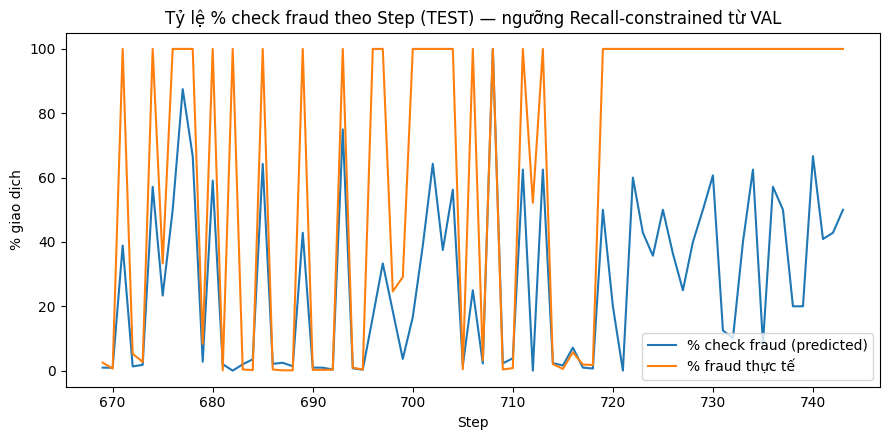

In [ ]:
# cell 15 (REPLACED)
# @title TEST metrics using recall-constrained threshold from VAL
import numpy as np, torch
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, average_precision_score
)

test_metrics = evaluate_logits(model, test_loader, CFG["device"])
y_true = test_metrics["y_true"].astype(np.int32)
z_raw  = test_metrics["y_logit"].astype(np.float32)

with torch.no_grad():
    zt = torch.tensor(z_raw, dtype=torch.float32)
    if 'CALIB_SCALER' in globals() and CALIB_SCALER is not None:
        zt = CALIB_SCALER(zt)
    y_prob = torch.sigmoid(zt).cpu().numpy()

t = float(CALIB_T)
y_pred = (y_prob >= t).astype(int)
pred_rate = float(y_pred.mean())

prec = precision_score(y_true, y_pred, zero_division=0)
rec  = recall_score(y_true, y_pred, zero_division=0)
f1   = f1_score(y_true, y_pred, zero_division=0)
roc  = roc_auc_score(y_true, y_prob)
pr   = average_precision_score(y_true, y_prob)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()

print(f"Test ROC-AUC: {roc:.4f}")
print(f"Test PR-AUC : {pr:.4f}")
print(f"[TEST] Threshold source: {CALIB_SRC} | t={t:.6f}")
print(f"[TEST] predicted_pos_rate: {pred_rate*100:.4f}%")
print(f"[TEST] Precision={prec:.4f} | Recall={rec:.4f} | F1={f1:.4f}")
print(f"[TEST] Confusion matrix: TP={tp} | FP={fp} | FN={fn} | TN={tn}")

# Plot % check theo Step như trước (dùng t)
import numpy as np, pandas as pd, matplotlib.pyplot as plt

test_idx = TEST_EIDX.detach().cpu().numpy() if hasattr(TEST_EIDX, 'detach') else np.asarray(TEST_EIDX)
steps_test = df[C_STEP].to_numpy()[test_idx]
g = pd.DataFrame({"step": steps_test, "y_true": y_true, "y_pred": y_pred}).groupby("step", sort=True)
step_vals = g.size().index.values
pred_rate_step = g["y_pred"].mean().values * 100.0
true_rate_step = g["y_true"].mean().values * 100.0

plt.figure(figsize=(9,4.5))
plt.plot(step_vals, pred_rate_step, label="% check fraud (predicted)")
plt.plot(step_vals, true_rate_step, label="% fraud thực tế")
plt.title("Tỷ lệ % check fraud theo Step (TEST) — ngưỡng Recall-constrained từ VAL")
plt.xlabel("Step"); plt.ylabel("% giao dịch"); plt.legend(); plt.tight_layout()


In [ ]:
# ===== 15c (FIXED) — Apply TAU_SEG to TEST + cache arrays =====
import numpy as np, torch

# Probabilities sau calibration
Y_PROB_TEST = P_TEST_CAL.copy()

# STEP & SEGMENT trên TEST
STEPS_TEST = df.loc[TEST_IDX, C_STEP].to_numpy().astype(int)
seg_test   = TEST_SEG.astype(int)

# Tạo mask kết quả
SEG_MASK = np.zeros_like(Y_PROB_TEST, dtype=bool)
fallback_used = 0

for key in np.unique(seg_test):
    m = seg_test == key

    # NGƯỠNG SEGMENT → dùng TAU_SEG (đúng)
    t = TAU_SEG.get(int(key), None)

    # Nếu không có trong TAU_SEG (nhóm quá nhỏ) → fallback
    if t is None:
        t = T_MIN_GLOBAL
        fallback_used += int(m.sum())

    SEG_MASK[m] = Y_PROB_TEST[m] >= t

print(f"[15c] Applied TAU_SEG to TEST | segments={len(TAU_SEG)} | fallback_used={fallback_used}")

# giữ để dùng về sau
Y_PRED_SEG = SEG_MASK.astype(int)


[15c] Applied TAU_SEG to TEST | segments=2 | fallback_used=11427


In [ ]:
# 15d_fix — no-op
print("[15d_fix] skipped (obsolete).")


[15d_fix] skipped (obsolete).


In [ ]:
#15e — no-op
print("[15e] skipped (obsolete schedule).")


[15e] skipped (obsolete schedule).


In [ ]:
# 15f_merge — no-op
print("[15f_merge] skipped (obsolete merge).")


[15f_merge] skipped (obsolete merge).


In [ ]:
# 15rm_new_new — Simple per-step top-K scheduling (no segment thresholds)
import numpy as np
from collections import defaultdict
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

# 1) Xác định xác suất dùng để ranking
#    Ở đây dùng trực tiếp P_TEST_CAL (không nhân SEG_MULT, không dùng TAU_SEG)
PROB = P_TEST_CAL.copy()

# 2) Chuẩn bị index theo step
steps = TEST_STEP.astype(int)
uniq_steps = np.unique(steps)
idx_by_step = {int(s): np.where(steps == s)[0] for s in uniq_steps}

# 3) Áp dụng STEP_CAP: mỗi step chọn top-K theo cap của step
Y_PRED_FINAL = np.zeros_like(PROB, dtype=bool)
total_selected = 0

for s in uniq_steps:
    ids = idx_by_step[s]
    n_s = len(ids)
    if n_s == 0:
        continue

    # lấy cap của step; nếu thiếu thì dùng trung bình
    cap_s = float(STEP_CAP.get(s, STEP_CAP.mean()))
    cap_s = float(np.clip(cap_s, 0.0, 1.0))

    # số giao dịch cần chọn tại step này
    k_s = int(round(cap_s * n_s))
    if k_s <= 0:
        continue
    k_s = min(k_s, n_s)

    # chọn top-k_s theo PROB trong step s
    order = ids[np.argsort(-PROB[ids])]
    pick = order[:k_s]

    Y_PRED_FINAL[pick] = True
    total_selected += len(pick)

pred_rate = Y_PRED_FINAL.mean() * 100.0

# 4) Metrics
y_true = y_test

prec = precision_score(y_true, Y_PRED_FINAL, zero_division=0)
rec  = recall_score(y_true, Y_PRED_FINAL, zero_division=0)
f1   = f1_score(y_true, Y_PRED_FINAL, zero_division=0)
roc  = roc_auc_score(y_true, PROB)
pr   = average_precision_score(y_true, PROB)
tn, fp, fn, tp = confusion_matrix(y_true, Y_PRED_FINAL, labels=[0,1]).ravel()

print(f"[15rm_new_new] pred_rate={pred_rate:.2f}% | "
      f"P={prec:.4f} R={rec:.4f} F1={f1:.4f} | ROC-AUC={roc:.4f} PR-AUC={pr:.4f}")
print(f"[15rm_new_new] CM: TP={tp} FP={fp} FN={fn} TN={tn}")


[15rm_new_new] pred_rate=1.52% | P=0.1224 R=0.1513 F1=0.1353 | ROC-AUC=0.8989 PR-AUC=0.3209
[15rm_new_new] CM: TP=128 FP=918 FN=718 TN=67084


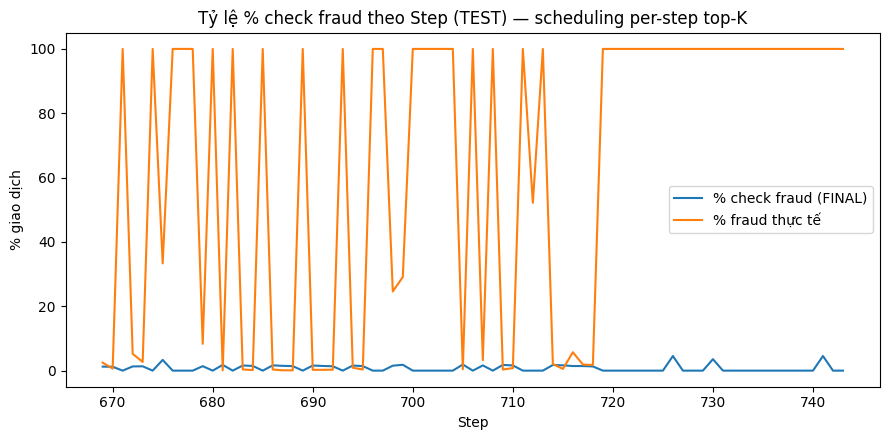

In [ ]:
# 15g_fix — plot theo step với Y_PRED_FINAL mới
import pandas as pd, matplotlib.pyplot as plt

g = pd.DataFrame({
    "step": TEST_STEP,
    "y_true": y_test,
    "y_pred": Y_PRED_FINAL.astype(int)
}).groupby("step", sort=True).agg(
    pred_rate=("y_pred","mean"),
    true_rate=("y_true","mean"),
)

steps = g.index.values
pr_step = g["pred_rate"].values * 100.0
tr_step = g["true_rate"].values * 100.0

plt.figure(figsize=(9,4.5))
plt.plot(steps, pr_step, label="% check fraud (FINAL)")
plt.plot(steps, tr_step, label="% fraud thực tế")
plt.xlabel("Step"); plt.ylabel("% giao dịch")
plt.title("Tỷ lệ % check fraud theo Step (TEST) — scheduling per-step top-K")
plt.legend(); plt.tight_layout()


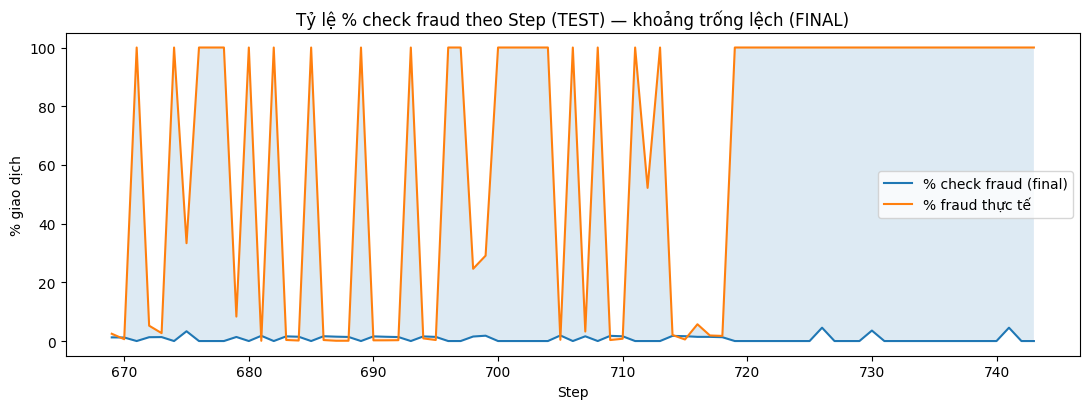

In [ ]:
# 15h — Plot khoảng trống lệch
import numpy as np, pandas as pd, matplotlib.pyplot as plt
g = pd.DataFrame({"step": TEST_STEP, "y_true": y_test, "y_pred": Y_PRED_FINAL}) \
        .groupby("step", sort=True).agg(true_rate=("y_true","mean"),
                                        pred_rate=("y_pred","mean"))
steps = g.index.values; tr = g["true_rate"].values * 100.0; pr = g["pred_rate"].values * 100.0
plt.figure(figsize=(11,4.2))
plt.plot(steps, pr, label="% check fraud (final)")
plt.plot(steps, tr, label="% fraud thực tế")
plt.fill_between(steps, pr, tr, where=(pr<tr), interpolate=True, alpha=0.15)
plt.fill_between(steps, pr, tr, where=(pr>tr), interpolate=True, alpha=0.10)
plt.title("Tỷ lệ % check fraud theo Step (TEST) — khoảng trống lệch (FINAL)")
plt.xlabel("Step"); plt.ylabel("% giao dịch"); plt.legend(); plt.tight_layout()


In [ ]:
#15x_check — median |gap| và thống kê step
import numpy as np, pandas as pd
g = pd.DataFrame({"step": TEST_STEP, "y_true": y_test, "y_pred": Y_PRED_FINAL}) \
        .groupby("step", sort=True).agg(true_rate=("y_true","mean"),
                                        pred_rate=("y_pred","mean"),
                                        n=("y_true","size"))
g["gap_abs"] = (g["pred_rate"] - g["true_rate"]).abs()
print("[15x] steps:", len(g), "| median n:", int(g["n"].median()),
      "| median |gap|:", f"{g['gap_abs'].median()*100:.2f}%")


[15x] steps: 75 | median n: 14 | median |gap|: 100.00%
